# Week 2 — Baseline Models

Objective: Compare baseline models for anomaly detection.

Use the existing dataset splits. Cross-validation uses training data only. Keep the test set untouched until model selection is complete.

## 1. Load the Existing Dataset Splits

In [14]:
import os
import sys
from pathlib import Path

PROJECT_ROOT = Path(r"E:\ml-engineer-internship")

os.chdir(PROJECT_ROOT)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)
print("src folder exists:", (PROJECT_ROOT / "src").exists())
print("Current directory:", Path.cwd())

Project root: E:\ml-engineer-internship
src folder exists: True
Current directory: E:\ml-engineer-internship


In [15]:
from src.pipeline import load_split_data

X_train, y_train, X_val, y_val, X_test, y_test = load_split_data()

print("Train rows:", len(X_train))
print("Validation rows:", len(X_val))
print("Test rows:", len(X_test))
print(f"Training anomaly rate: {y_train.mean():.2%}")

Train rows: 17500
Validation rows: 3750
Test rows: 3750
Training anomaly rate: 3.91%


## 2. Target Distribution

In [17]:
import pandas as pd

target_summary = pd.DataFrame({
    "split": ["train", "validation", "test"],
    "rows": [len(y_train), len(y_val), len(y_test)],
    "anomalies": [int(y_train.sum()), int(y_val.sum()), int(y_test.sum())],
})
target_summary["anomaly_rate"] = (
    target_summary["anomalies"] / target_summary["rows"]
)
target_summary

,split,rows,anomalies,anomaly_rate
0,train,17500,685,0.039143
1,validation,3750,147,0.039200
2,test,3750,147,0.039200


## 3. Stratified 5-Fold Cross-Validation

Preprocessing is kept inside each model pipeline. This prevents imputation, scaling, and encoding from learning from a validation fold during cross-validation.

In [18]:
from pathlib import Path
from src.evaluation import evaluate_baselines_cv

results_path = Path("reports/baseline_results.csv")

if results_path.exists():
    results = pd.read_csv(results_path)
    print("Loaded saved results:", results_path)
else:
    results = evaluate_baselines_cv(
        X_train, y_train, n_splits=5
    )
    results_path.parent.mkdir(parents=True, exist_ok=True)
    results.to_csv(results_path, index=False)
    print("Saved results:", results_path)

results.sort_values("pr_auc_mean", ascending=False).round(4)

Loaded saved results: reports\baseline_results.csv


,model,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std
0,logistic_regression,0.8391,0.0072,0.1459,0.0090,0.6394,0.0367,0.2375,0.0140,0.7910,0.0168,0.2112,0.0235
1,random_forest,0.9542,0.0007,0.3117,0.0135,0.1416,0.0151,0.1945,0.0158,0.7769,0.0254,0.1836,0.0135
2,decision_tree,0.8347,0.0103,0.1378,0.0100,0.6131,0.0694,0.2248,0.0169,0.6951,0.0435,0.1717,0.0284
3,knn,0.9607,0.0002,0.1000,0.2236,0.0015,0.0033,0.0029,0.0064,0.6110,0.0114,0.0691,0.0088
4,dummy_stratified,0.9227,0.0014,0.0361,0.0173,0.0380,0.0182,0.0370,0.0177,0.4983,0.0095,0.0393,0.0008
5,dummy_most_frequent,0.9609,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.5000,0.0000,0.0391,0.0000


## 4. Compare PR-AUC and ROC-AUC

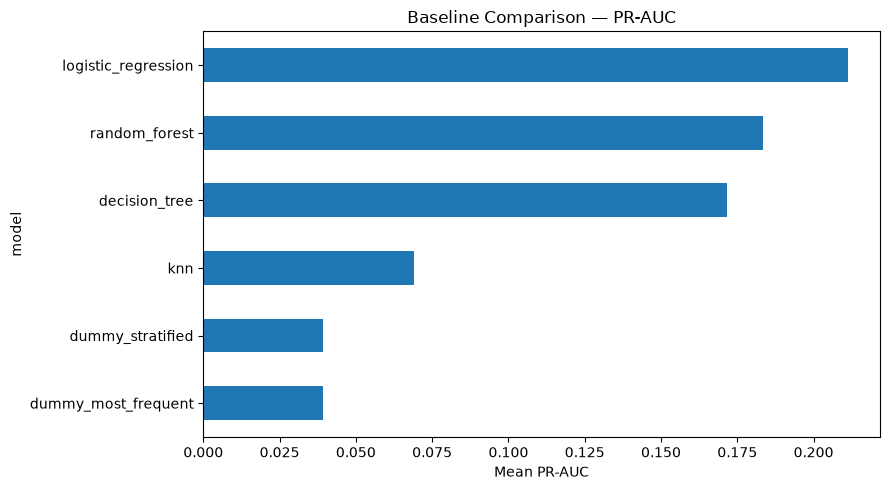

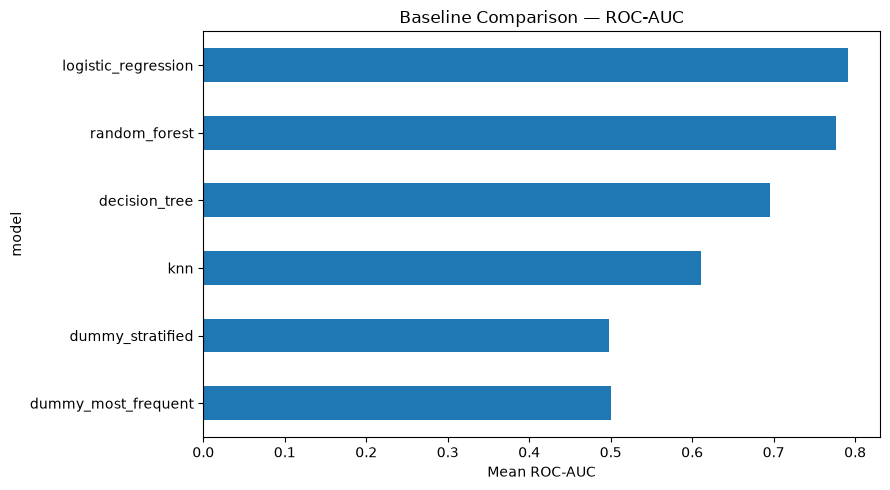

In [19]:
import matplotlib.pyplot as plt

plot_data = results.sort_values("pr_auc_mean")

plot_data.plot.barh(
    x="model", y="pr_auc_mean", legend=False, figsize=(9, 5)
)
plt.title("Baseline Comparison — PR-AUC")
plt.xlabel("Mean PR-AUC")
plt.tight_layout()
plt.show()

plot_data.plot.barh(
    x="model", y="roc_auc_mean", legend=False, figsize=(9, 5)
)
plt.title("Baseline Comparison — ROC-AUC")
plt.xlabel("Mean ROC-AUC")
plt.tight_layout()
plt.show()

## 5. Cross-Validation Variability

In [20]:
results[["model", "roc_auc_std", "pr_auc_std"]].round(4)

,model,roc_auc_std,pr_auc_std
0,logistic_regression,0.0168,0.0235
1,random_forest,0.0254,0.0135
2,decision_tree,0.0435,0.0284
3,knn,0.0114,0.0088
4,dummy_stratified,0.0095,0.0008
5,dummy_most_frequent,0.0000,0.0000


## 6. Findings and Limitations

- Logistic Regression currently has the highest mean PR-AUC among the tested models.
- Accuracy alone is misleading for an imbalanced dataset.
- KNN has very low recall at the default prediction threshold.
- Compare CV standard deviations with the roadmap target of 0.005; do not assume this criterion is satisfied.
- These are baseline results, not final tuned-model results.
- Do not use the test set to select models or thresholds.